# Control óptimo de EDOs — Clase 2
**El problema básico y el Principio del Máximo**

FCEN–UBA. Bibliografía principal: Lenhart & Workman, *Optimal Control Applied to Biological Models* (2007).

> Convención del curso: problemas de **máximo** y Hamiltoniano $H = L + \lambda f$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp, solve_bvp
from scipy.optimize import brentq, minimize
plt.rcParams.update({'figure.figsize': (7, 3.5), 'axes.grid': True, 'grid.alpha': 0.3})

def integral(v, t):
    """Regla del trapecio."""
    return float(np.sum(0.5*(v[1:] + v[:-1])*np.diff(t)))

## 1. Multiplicadores de Lagrange y precio sombra
$\max y_1y_2$ sujeto a $y_1+y_2=c$. A mano: $y_1=y_2=c/2$, $\lambda=-c/2$, $F^*(c)=c^2/4$ y $\frac{dF^*}{dc}=-\lambda$.
Lo verificamos resolviendo numéricamente el problema con restricción (`SLSQP`) para varios $c$.

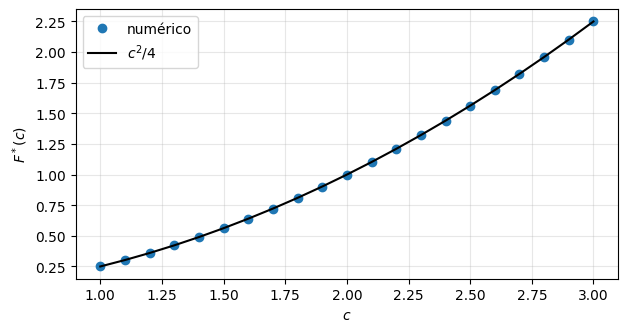

c=2: y* = [1. 1.],  lambda = -1.0000
dF*/dc (diferencias finitas) = 1.0000   -lambda = 1.0000   (precio sombra)


In [2]:
def resolver(c):
    r = minimize(lambda y: -y[0]*y[1], x0=[0.3, 0.7], method='SLSQP',
                 constraints=[{'type': 'eq', 'fun': lambda y: y[0] + y[1] - c}])
    y = r.x
    lam = -y[1]                      # de la condición  y2 + lam = 0
    return y, -r.fun, lam

cs = np.linspace(1, 3, 21)
Fstar = [resolver(c)[1] for c in cs]
plt.plot(cs, Fstar, 'o', label='numérico'); plt.plot(cs, cs**2/4, 'k-', label='$c^2/4$')
plt.xlabel('$c$'); plt.ylabel('$F^*(c)$'); plt.legend(); plt.show()

y, F2, lam = resolver(2.0)
h = 1e-4
dF = (resolver(2 + h)[1] - resolver(2 - h)[1])/(2*h)
print(f'c=2: y* = {y},  lambda = {lam:.4f}')
print(f"dF*/dc (diferencias finitas) = {dF:.4f}   -lambda = {-lam:.4f}   (precio sombra)")

## 2. Ejemplo 1: $\max\int_0^1(x-u^2)$, $\dot x=u$, $x(0)=0$
PMP: $u=\lambda/2$, $\dot\lambda=-1$, $\lambda(1)=0$. A mano: $\lambda=1-t$, $u^*=\frac{1-t}{2}$, $x^*=\frac t2-\frac{t^2}4$.

Resolvemos el **problema de valores de frontera** con `solve_bvp` y comparamos.

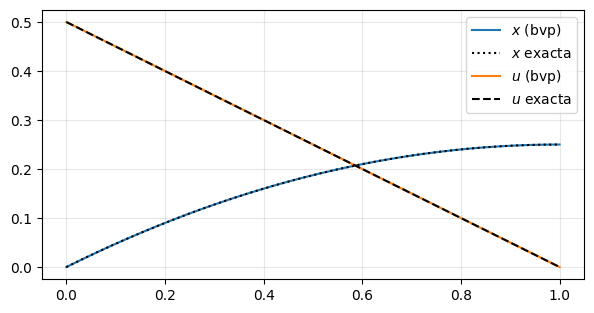

error máx en u: 2.220446049250313e-16


In [3]:
def sistema1(t, y):                 # y = (x, lambda)
    x, lam = y
    return np.vstack([lam/2, -np.ones_like(lam)])

bordes1 = lambda ya, yb: np.array([ya[0] - 0.0, yb[1] - 0.0])   # x(0)=0, lambda(1)=0
t = np.linspace(0, 1, 50)
sol1 = solve_bvp(sistema1, bordes1, t, np.zeros((2, t.size)))
tt = np.linspace(0, 1, 300); x1, l1 = sol1.sol(tt); u1 = l1/2
plt.plot(tt, x1, label='$x$ (bvp)'); plt.plot(tt, tt/2 - tt**2/4, 'k:', label='$x$ exacta')
plt.plot(tt, u1, label='$u$ (bvp)'); plt.plot(tt, (1 - tt)/2, 'k--', label='$u$ exacta')
plt.legend(); plt.show()
print('error máx en u:', np.abs(u1 - (1 - tt)/2).max())

**Chequeos de la Clase 2:**
* Legendre–Clebsch: $H_{uu}=-2<0$.
* Mangasarian: $\nabla^2_{(x,u)}H=\begin{pmatrix}0&0\\0&-2\end{pmatrix}\preceq0$ $\Rightarrow$ es el óptimo.
* Problema autónomo $\Rightarrow$ $H=x-u^2+\lambda u$ es constante (debería dar $1/4$).

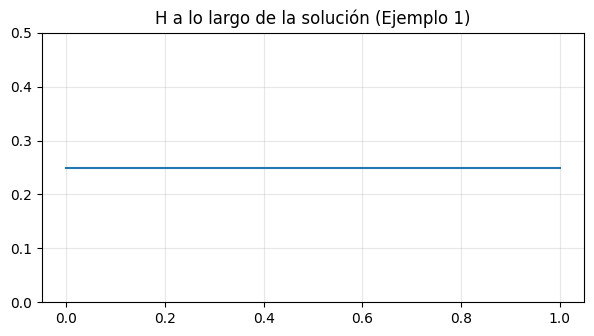

H min / max: 0.25000000000000006 0.25000000000000033


In [4]:
H1 = x1 - u1**2 + l1*u1
plt.plot(tt, H1); plt.ylim(0, 0.5); plt.title('H a lo largo de la solución (Ejemplo 1)'); plt.show()
print('H min / max:', H1.min(), H1.max())

## 3. Ejemplo 2: $\min\frac12\int_0^1(3x^2+u^2)$, $\dot x=x+u$, $x(0)=1$
PMP (como máximo): $u=\lambda$, $\dot\lambda=3x-\lambda$, $\lambda(1)=0$: el sistema lineal con la matriz $\begin{pmatrix}1&1\\3&-1\end{pmatrix}$ de la Clase 1.

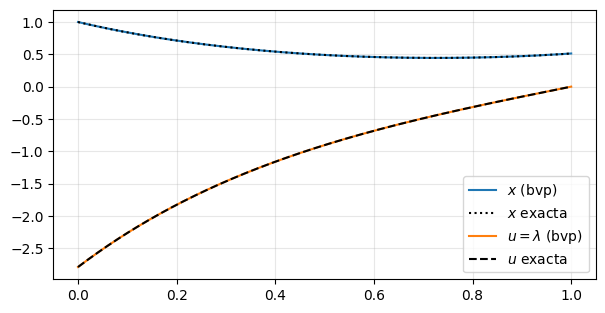

error máx en u: 2.254521769273765e-08
H constante: -0.39497727189235654 -0.3949772661820682   teoría: -3/2 x(1)^2 = -0.3949772664359733


In [5]:
sistema2 = lambda t, y: np.vstack([y[0] + y[1], 3*y[0] - y[1]])
bordes2 = lambda ya, yb: np.array([ya[0] - 1.0, yb[1]])
sol2 = solve_bvp(sistema2, bordes2, t, np.zeros((2, t.size)))
c = 3*np.exp(-4)/(3*np.exp(-4) + 1); d = 1/(3*np.exp(-4) + 1)
x_ex = c*np.exp(2*tt) + d*np.exp(-2*tt); u_ex = c*np.exp(2*tt) - 3*d*np.exp(-2*tt)
x2, l2 = sol2.sol(tt)
plt.plot(tt, x2, label='$x$ (bvp)'); plt.plot(tt, x_ex, 'k:', label='$x$ exacta')
plt.plot(tt, l2, label='$u=\\lambda$ (bvp)'); plt.plot(tt, u_ex, 'k--', label='$u$ exacta')
plt.legend(); plt.show()
print('error máx en u:', np.abs(l2 - u_ex).max())
H2 = -1.5*x2**2 - 0.5*l2**2 + l2*(x2 + l2)
print('H constante:', H2.min(), H2.max(), '  teoría: -3/2 x(1)^2 =', -1.5*x_ex[-1]**2)

### ¿Algún control le gana al del PMP?
Simulamos controles perturbados y calculamos el costo (a minimizar).

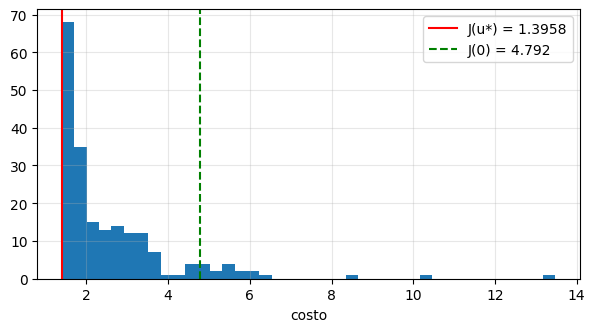

mínimo de los perturbados: 1.402583820253548


In [6]:
tg = np.linspace(0, 1, 2001)
u_opt = c*np.exp(2*tg) - 3*d*np.exp(-2*tg)

def costo2(u):
    s = solve_ivp(lambda s, x: x + np.interp(s, tg, u), [0, 1], [1.0], t_eval=tg, rtol=1e-9)
    return 0.5*integral(3*s.y[0]**2 + u**2, tg)

rng = np.random.default_rng(0)
vals = [costo2(u_opt + 0.6*(a[0] + a[1]*tg + a[2]*np.sin(np.pi*tg) + a[3]*np.cos(3*tg)))
        for a in rng.normal(size=(200, 4))]
plt.hist(vals, bins=40); plt.axvline(costo2(u_opt), color='r', label=f'J(u*) = {costo2(u_opt):.4f}')
plt.axvline(costo2(0*tg), color='g', ls='--', label=f'J(0) = {costo2(0*tg):.3f}')
plt.legend(); plt.xlabel('costo'); plt.show()
print('mínimo de los perturbados:', min(vals))

## 4. Ejemplo 3: el PMP da candidatos, no garantías
$\max\int_0^1u^2$, $\dot x=u$. El único candidato es $u\equiv0$, pero $J(k)=k^2\to\infty$: no hay máximo.

In [7]:
for k in [0, 1, 2, 5, 10]:
    print(f'u = {k:3d}:  J = {integral(np.full_like(tg, k)**2, tg):8.2f}')
print('H_uu = 2 > 0: viola Legendre-Clebsch para un máximo. Para el MÍNIMO, u=0 sí es óptimo (H=-u^2+lam u es cóncava).')

u =   0:  J =     0.00
u =   1:  J =     1.00
u =   2:  J =     4.00
u =   5:  J =    25.00
u =  10:  J =   100.00
H_uu = 2 > 0: viola Legendre-Clebsch para un máximo. Para el MÍNIMO, u=0 sí es óptimo (H=-u^2+lam u es cóncava).


## 5. Ejercicios 1 y 2
**Ejercicio 1:** $\min\int_0^1(x^2+u^2)$, $\dot x=u$, $x(0)=1$. Se espera $x^*=\cosh(1-t)/\cosh1$ y $u^*(0)=-\tanh 1$.

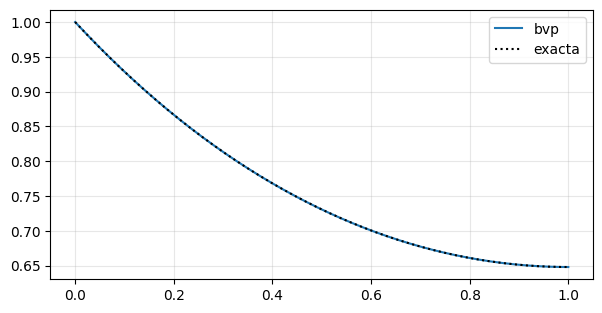

u*(0) = -0.7615941558545799    -tanh(1) = -0.7615941559557649


In [8]:
# H = -x^2 - u^2 + lam*u  ->  u = lam/2,  lam' = 2x
sol_e1 = solve_bvp(lambda t, y: np.vstack([y[1]/2, 2*y[0]]),
                   lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]), t, np.zeros((2, t.size)))
plt.plot(tt, sol_e1.sol(tt)[0], label='bvp'); plt.plot(tt, np.cosh(1 - tt)/np.cosh(1), 'k:', label='exacta')
plt.legend(); plt.show()
print('u*(0) =', sol_e1.sol(0)[1]/2, '   -tanh(1) =', -np.tanh(1))

**Ejercicio 2:** $\max\int_0^2(x-2u^2)$, $\dot x=-x+u$, $x(0)=1$. Completar el sistema y comparar con la solución a mano
($\lambda=1-e^{t-2}$, $u^*=\lambda/4$).

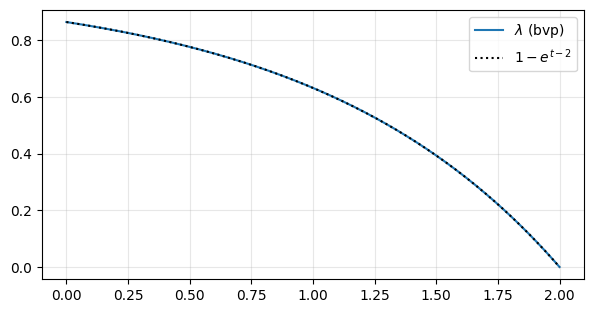

In [9]:
# Completar: H = x - 2u^2 + lam(-x + u)
def sistema_e2(t, y):
    x, lam = y
    u = lam/4
    return np.vstack([-x + u, -1 + lam])          # lam' = -H_x = -1 + lam

t2 = np.linspace(0, 2, 60)
sol_e2 = solve_bvp(sistema_e2, lambda ya, yb: np.array([ya[0] - 1.0, yb[1]]), t2, np.zeros((2, t2.size)))
tt2 = np.linspace(0, 2, 300)
plt.plot(tt2, sol_e2.sol(tt2)[1], label='$\\lambda$ (bvp)'); plt.plot(tt2, 1 - np.exp(tt2 - 2), 'k:', label='$1-e^{t-2}$')
plt.legend(); plt.show()

## 6. Ejercicio 5: sensibilidad respecto del dato inicial
En el Ejemplo 1 con $x(0)=\eta$, el valor óptimo es $J^*(\eta)=\eta+\frac1{12}$. Comparamos $\frac{dJ^*}{d\eta}$ con $\lambda(0)$:
el adjunto es el **precio sombra** del estado.

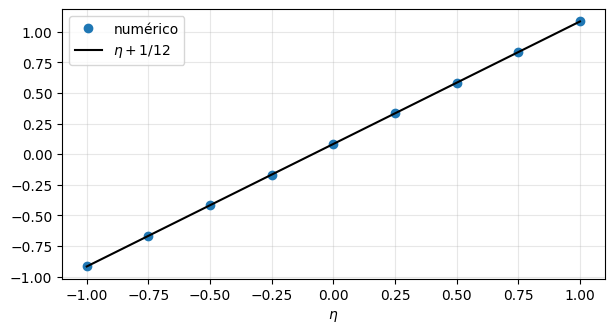

dJ*/deta = 0.9999999999999939    lambda(0) = 1.0000000000000004


In [10]:
def Jstar(eta):
    s = solve_bvp(sistema1, lambda ya, yb: np.array([ya[0] - eta, yb[1]]), t, np.zeros((2, t.size)))
    x, l = s.sol(tt)
    return integral(x - (l/2)**2, tt), s.sol(0)[1]

etas = np.linspace(-1, 1, 9)
J_vals = [Jstar(e)[0] for e in etas]
plt.plot(etas, J_vals, 'o', label='numérico'); plt.plot(etas, etas + 1/12, 'k-', label='$\\eta+1/12$')
plt.xlabel('$\\eta$'); plt.legend(); plt.show()
h = 1e-3
print('dJ*/deta =', (Jstar(h)[0] - Jstar(-h)[0])/(2*h), '   lambda(0) =', Jstar(0)[1])

## 7. El gradiente: $\frac{d}{d\varepsilon}J(u+\varepsilon h)\big|_0=\int H_u\,h$
La deducción del PMP no usó la optimalidad hasta el final: para **cualquier** $u$, si $\lambda$ resuelve la adjunta
con ese $u$, el gradiente de $J$ es $H_u$. Lo verificamos con diferencias finitas en el Ejemplo 2
(versión máximo, $J=-\frac12\int(3x^2+u^2)$, $H_u=-u+\lambda$). Es la idea de *backpropagation* (Clase 4).

In [11]:
N = 4000
tg = np.linspace(0, 1, N+1)
def J_y_grad(u):
    x = solve_ivp(lambda s, x: x + np.interp(s, tg, u), [0, 1], [1.0], t_eval=tg, rtol=1e-10, atol=1e-12).y[0]
    lam = solve_ivp(lambda s, l: 3*np.interp(s, tg, x) - l, [1, 0], [0.0], t_eval=tg[::-1],
                    rtol=1e-10, atol=1e-12).y[0][::-1]
    return -0.5*integral(3*x**2 + u**2, tg), -u + lam

u = np.sin(3*tg); h = tg**2 - 0.5
J0, Hu = J_y_grad(u)
eps = 1e-5
dJ_fd = (J_y_grad(u + eps*h)[0] - J_y_grad(u - eps*h)[0])/(2*eps)
print(f'diferencias finitas: {dJ_fd:.6f}   fórmula con el adjunto: {integral(Hu*h, tg):.6f}')

diferencias finitas: 2.100553   fórmula con el adjunto: 2.100398


## 8. Ejercicio 6 (a mano): publicidad, modelo de Nerlove–Arrow
$\max\int_0^T(pG-\frac12u^2)$, $\dot G=u-\delta G$, $G(0)=G_0$. Resolverlo a mano y **después** comparar con `solve_bvp`.
La solución a mano debería dar $\lambda(t)=\frac p\delta\big(1-e^{-\delta(T-t)}\big)$ y $u^*=\lambda$.

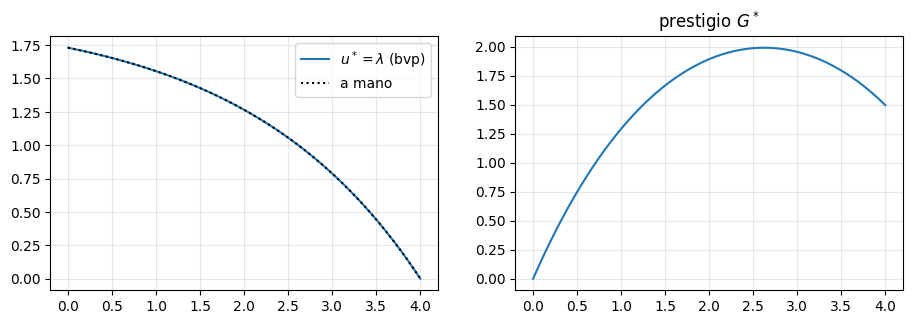

H constante: 1.495290143114068 1.4952901465853063


In [12]:
p, delta, G0, T6 = 1.0, 0.5, 0.0, 4.0
sist6 = lambda t, y: np.vstack([y[1] - delta*y[0], -p + delta*y[1]])    # (G, lambda), u = lambda
t6 = np.linspace(0, T6, 60)
sol6 = solve_bvp(sist6, lambda ya, yb: np.array([ya[0] - G0, yb[1]]), t6, np.zeros((2, t6.size)))
tt6 = np.linspace(0, T6, 300); G6, l6 = sol6.sol(tt6)
lam_mano = p/delta*(1 - np.exp(-delta*(T6 - tt6)))          # <- comparar con tu cuenta
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(tt6, l6, label='$u^*=\\lambda$ (bvp)'); ax[0].plot(tt6, lam_mano, 'k:', label='a mano'); ax[0].legend()
ax[1].plot(tt6, G6); ax[1].set_title('prestigio $G^*$')
plt.show()
H6 = p*G6 - 0.5*l6**2 + l6*(l6 - delta*G6)
print('H constante:', H6.min(), H6.max())

## 9. Ejercicio 7 (numérico): dosis de carga y de mantenimiento
$\min\int_0^T\big((x-\bar x)^2+c\,u^2\big)$, $\dot x=-\frac{Vx}{K+x}+u$, $x(0)=0$.

Como máximo: $H=-(x-\bar x)^2-cu^2+\lambda\big(-\frac{Vx}{K+x}+u\big)$, así que $u^*=\frac{\lambda}{2c}$ y
$\dot\lambda=-H_x=2(x-\bar x)+\lambda\frac{VK}{(K+x)^2}$, $\lambda(T)=0$.

El sistema es **no lineal**: no se resuelve a mano. Completar `sistema7` y resolver con `solve_bvp`.
Ayuda: dar como semilla $x\equiv\bar x$ (la cercanía de la semilla importa en problemas no lineales).

The algorithm converged to the desired accuracy.


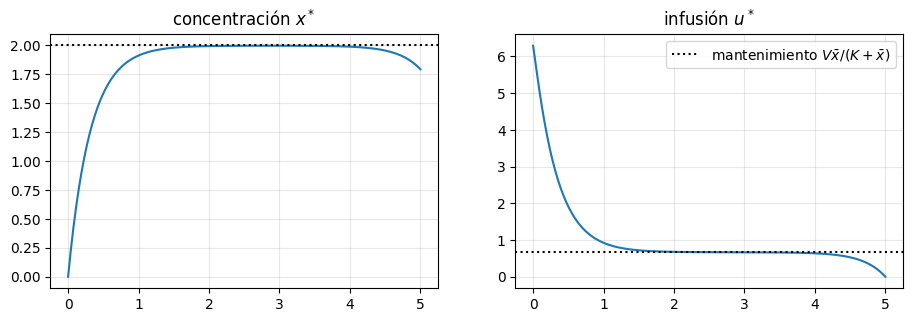

H constante: -0.04438963270411733 -0.04438959646401329


In [13]:
V, K, xbar, c7, T7 = 1.0, 1.0, 2.0, 0.1, 5.0

def sistema7(t, y):
    x, lam = y
    u = lam/(2*c7)
    return np.vstack([-V*x/(K + x) + u, 2*(x - xbar) + lam*V*K/(K + x)**2])

t7 = np.linspace(0, T7, 200)
semilla = np.vstack([np.full_like(t7, xbar), np.zeros_like(t7)])
sol7 = solve_bvp(sistema7, lambda ya, yb: np.array([ya[0] - 0.0, yb[1]]), t7, semilla, tol=1e-6, max_nodes=20000)
print(sol7.message)
tt7 = np.linspace(0, T7, 400); x7, l7 = sol7.sol(tt7); u7 = l7/(2*c7)
u_mant = V*xbar/(K + xbar)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
ax[0].plot(tt7, x7); ax[0].axhline(xbar, ls=':', c='k'); ax[0].set_title('concentración $x^*$')
ax[1].plot(tt7, u7); ax[1].axhline(u_mant, ls=':', c='k', label='mantenimiento $V\\bar x/(K+\\bar x)$')
ax[1].set_title('infusión $u^*$'); ax[1].legend()
plt.show()
H7 = -(x7 - xbar)**2 - c7*u7**2 + l7*(-V*x7/(K + x7) + u7)
print('H constante:', H7.min(), H7.max())

**Para interpretar:** (1) *dosis de carga* al principio para llegar rápido a $\bar x$; (2) *mantenimiento* con
$u\approx V\bar x/(K+\bar x)$, que compensa exactamente la eliminación; (3) al final la infusión baja a $0$ porque
$\lambda(T)=0$: lo que pase después de $T$ no cuenta. Probar con $T=10$, $c=1$ y $c=0.01$.

## Para explorar
1. **Ascenso por gradiente:** $u^{k+1}=u^k+s\,H_u$ con $s=0.5$, partiendo de $u=0$ en el Ejemplo 2. ¿Converge a $u^*$?
2. Verificar numéricamente que en el Ejemplo 2 $H$ es constante también si cambiás $T$ (por ejemplo $T=2$).
3. En la sección 1, cambiar el objetivo por $\max y_1^2y_2$ y repetir el chequeo del precio sombra.